# Solar System Visibility Checker
A companion to `target_visibility.ipynb` for planets, their major moons and the dwarf planet Ceres, whose positions come from [JPL Horizons](https://ssd.jpl.nasa.gov/horizons/) instead of a fixed sky coordinate.

- **Cell 1**: imports. The helper functions live in `helpers.py` and `solar_system_helpers.py` beside this notebook.
- **Cell 2**: everything you edit: `targets_list`, the UTC start/stop, the cadence, the TLE and the `Visibility` settings.
- **Cell 3**: ephemerides of every body in each target's system from Horizons, with how often each moon is free and clear.
- **Cell 4**: visibility per target, one best-roll search per day.
- **Cell 5**: the pointing RA and Dec over time (also as a J2000 ECI unit vector x, y, z), and how far each body of the system is from the target.
- **Cell 6**: one timeline per target: when it is visible, and when each body of its system is free and clear.
- **Cell 7**: which pointing constraint is failing while the target is not visible.
- **Cell 8**: the simulated NIRDA subarray each day, at the roll held that day.
- **Cell 9**: the simulated VISDA star field each day, at the roll held that day.
- **Cell 10**: one CSV per target of visibility, pointing and roll at every time step.
- **Cell 11**: when each target is observable (visible, clear, and for a moon not too close in front of or behind its planet), with its pointing, orbital phase, phase angle and whether a glint off surface liquid is possible.

A target can be a planet (`"Saturn"`), a major moon (`"Titan"`) or a dwarf planet (`"Ceres"`); see `PLANETS`, `MAJOR_MOONS` and `DWARF_PLANETS` in `solar_system_helpers.py` for the names known. Each target is put at the NIRDA pivot in turn, and the rest of its system (the planet and its major moons) is drawn around it.

Horizons is queried over the internet once per body. Its positions are geocentric: Pandora's ~7,000 km offset from the Earth's center moves every body of a planetary system by the same ~1 arcsec, so the geometry between them, which decides occultations and trace overlaps, is unchanged. The NIRDA and VISDA panels also use the offline Gaia DR3 catalog from `gaiaoffline` for field stars; set `include_field_stars = False` in Cell 2 to run without it.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from matplotlib.patches import Patch

from helpers import (
    build_time_grid,
    draw_event_box,
    draw_row,
    format_date_axis,
    label_rows,
    mask_segments,
    run_stats,
)
from solar_system_helpers import (
    LIQUID_FEATURES,
    TITAN_LIQUID_INDEX,
    VISIBILITY_CODES,
    fresnel_reflectance,
    glint_check,
    illuminated_disk,
    is_clear,
    is_primary,
    mean_coord,
    moon_geometry,
    pandora_centric,
    resolve_body,
    specular_point,
    system_ephemerides,
    system_field,
    system_visible_sources,
    system_ids,
)
from pandoravisibility import Visibility, trace, version, visda

print(f"Pandora Visibility Version: {version}.")

Pandora Visibility Version: 2.1.0.


## Edit this cell

`targets_list` takes planet, major moon and dwarf planet (Ceres) names, mixed freely. The keep-outs are the same settings as `target_visibility.ipynb`. The NIRDA trace check of the roll search is switched off here: it needs the target to be a Gaia star, which planets and moons are not, so it would only skip them with a warning. Cell 8 draws the system's traces instead.

In [2]:
# Targets: planets, major moons or Ceres, by name
targets_list = ["Titan"]

# Time window (UTC) and cadence. Each day of the window gets its own roll.
start_utc = "2026-11-06T00:00:00"
stop_utc = "2026-12-05T23:59:00"
time_step_minutes = 3.0

# Spacecraft orbit
# Placeholder TLE for Pandora (epoch 2026-10-21); use the newest one for real work!
line1 = "1 67395U 26004AJ  26306.47873105  .00000350  00000-0  43843-4 0  9998"
line2 = "2 67395  97.8123 303.0710 0006221  45.1274 315.0446 14.88248860 43841"

# The class defaults as of v2.1.0, spelled out so the run stays pinned if the
# defaults move again. Change any of them here, e.g. st_required=2.
visibility_settings = dict(
    earthlimb_day_min=44 * u.deg,
    earthlimb_night_min=13 * u.deg,
    sun_min=91 * u.deg,
    moon_min=20 * u.deg,
    st_sun_min=50 * u.deg,
    st_moon_min=20 * u.deg,
    st_earthlimb_min=30 * u.deg,
    st_required=1,
    use_dynamic_earthlimb=True,
    # Sun/Moon evaluated hourly and interpolated; directions stay good to well
    # under 0.01 deg. Drop this line to evaluate the ephemeris exactly.
    ephemeris_step=60 * u.min,
    # Off: the roll search's trace check needs a Gaia star at the target.
    use_trace_sweep=True,
    # NIRDA subarray drawn in Cell 8
    nirda_roi_x=350,
    nirda_roi_y=512,
)
visibility = Visibility(line1, line2, **visibility_settings)

# Roll sweep resolution for the optimize_roll search
roll_step = 1 * u.deg

# Gaia field stars in the Cell 8 panels (needs the gaiaoffline database)
include_field_stars = True

times = build_time_grid(start_utc, stop_utc, time_step_minutes)

print(visibility)
print(f"Orbital period: {visibility.get_period():.2f}")
print(f"{len(times)} steps of {time_step_minutes:g} min: "
      f"{times[0].iso} → {times[-1].iso}")

<Visibility: SAT67395 [moon≥20 deg, sun≥91 deg, limb=dynamic, st_sun≥50 deg, st_moon≥20 deg, st_limb≥30 deg, st_req=1]>
Orbital period: 96.76 min
14400 steps of 3 min: 2026-11-06 00:00:00.000 → 2026-12-05 23:57:00.000


## Ephemerides from JPL Horizons

One Horizons table per body, on the same time grid: astrometric position, visual magnitude, angular diameter, ring opening angle and pole position angle, and for moons a visibility code relative to their planet. Only **free and clear** (`*`) counts as observable; Horizons' other codes mean the moon is transiting the planet's disk, occulted by it, or in its shadow (eclipsed). Horizons treats the planet as a sphere of its equatorial radius and ignores rings, so a moon grazing the limb or behind the rings may be classed slightly wrong.

In [3]:
targets = [resolve_body(name) for name in targets_list]
target_ids = [target_id for target_id, _ in targets]
labels = {
    body_id: resolve_body(body_id)[1]
    for target_id in target_ids
    for body_id in system_ids(target_id)
}
ephemerides = system_ephemerides(
    target_ids, start_utc, stop_utc, time_step_minutes, times
)

shown_systems = []
for target_id in target_ids:
    system = system_ids(target_id)
    if system[0] in shown_systems:
        continue
    shown_systems.append(system[0])
    print(f"\n{labels[system[0]]} system")
    print(f"  {'Body':<11}{'V':>7}{'diameter':>10}{'clear':>8}  other states")
    for body_id in system:
        ephemeris = ephemerides[body_id]
        clear = is_clear(body_id, ephemeris)
        states = []
        if not is_primary(body_id):
            codes, counts = np.unique(ephemeris["code"][~clear], return_counts=True)
            states = [
                f"{VISIBILITY_CODES[code]} {100 * count / len(times):.1f}%"
                for code, count in zip(codes, counts)
            ]
        print(f"  {labels[body_id]:<11}{np.median(ephemeris['vmag']):>7.2f}"
              f"{np.median(ephemeris['diameter']):>9.2f}\""
              f"{100 * clear.mean():>7.1f}%  {', '.join(states)}")


Saturn system
  Body             V  diameter   clear  other states
  Saturn        0.56    18.97"  100.0%  
  Mimas        12.88     0.07"   79.0%  occulted by the planet 1.3%, occulted, partial umbral eclipse 0.0%, occulted, total umbral eclipse 8.6%, partial umbral eclipse 0.0%, transiting the planet's disk 10.3%, total umbral eclipse 0.8%
  Enceladus    11.68     0.08"   84.3%  occulted by the planet 1.4%, occulted, partial umbral eclipse 0.0%, occulted, total umbral eclipse 5.9%, partial umbral eclipse 0.0%, transiting the planet's disk 7.5%, total umbral eclipse 0.7%
  Tethys       10.18     0.17"   87.3%  occulted by the planet 1.5%, occulted, partial umbral eclipse 0.1%, occulted, total umbral eclipse 4.4%, partial umbral eclipse 0.1%, transiting the planet's disk 6.0%, total umbral eclipse 0.6%
  Dione        10.38     0.18"   92.1%  occulted by the planet 2.0%, occulted, partial umbral eclipse 0.1%, occulted, total umbral eclipse 1.8%, partial umbral eclipse 0.1%, transiting 

## Visibility per target

`get_visibility` with `optimize_roll=True` picks one roll per day, at the target's mean position that day (a planet moves well under 0.1° a day, against keep-outs of tens of degrees). The constraint diagnostics for Cell 7 are taken with the same roll the search held, as in `target_visibility.ipynb`.

Below the summary, each body of the target's system is listed with the share of the target's visible time during which that body is free and clear.

In [4]:
day_of = np.floor(times.jd - times[0].jd).astype(int)
days = np.unique(day_of)
results = {}

header = f"{'Target':<14}{'Visible':>13}{'Duty':>8}{'Windows':>9}{'Longest':>10}"
print(header)
print("-" * len(header))
for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = np.zeros(len(times), dtype=bool)
    roll_deg = np.full(len(times), np.nan)
    constraints, tracker_checks, limits = {}, {}, {}
    for day in days:
        indices = np.flatnonzero(day_of == day)
        day_times = times[indices]
        center = mean_coord(ephemeris, indices)
        run = visibility.get_visibility(
            center, day_times, optimize_roll=True, roll_step=roll_step
        )
        visible[indices] = run["visible"]
        roll_deg[indices] = run["roll_deg"]
        # Diagnostics at the roll the search held that day
        run_roll = run["roll_deg"] * u.deg
        for name, passed in visibility.get_all_constraints(
            center, day_times, roll=run_roll
        ).items():
            constraints.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        breakdown = visibility.get_star_tracker_breakdown(
            center, day_times, roll=run_roll
        )
        for name, passed in breakdown["passed"].items():
            tracker_checks.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        limits.update(breakdown["limits"])

    results[label] = {
        "id": target_id,
        "visible": visible,
        "roll_deg": roll_deg,
        "constraints": constraints,
        "tracker_checks": tracker_checks,
        "limits": limits,
    }
    n_windows, longest_minutes = run_stats(times, visible, time_step_minutes)
    print(f"{label:<14}{f'{visible.sum()} / {len(times)}':>13}"
          f"{100 * visible.mean():>7.1f}%{n_windows:>9}{longest_minutes:>8.0f} m")

for label, result in results.items():
    first_steps = [np.flatnonzero(day_of == day)[0] for day in days]
    print(f"\n{label}: roll held each day: " + ", ".join(
        f"{times[step].iso[5:10]} {result['roll_deg'][step]:+.0f}\u00b0"
        for step in first_steps))
    if not result["visible"].any():
        print("    not visible at any step")
        continue
    for body_id in system_ids(result["id"]):
        clear = is_clear(body_id, ephemerides[body_id])
        share = (result["visible"] & clear).sum() / result["visible"].sum()
        print(f"    {labels[body_id]:<11} free and clear for {100 * share:5.1f}% "
              f"of {label}'s visible time")

Target              Visible    Duty  Windows   Longest
------------------------------------------------------


C:\Users\jrenaud\Documents\venvs\pan13\Lib\site-packages\pandoravisibility\visibility.py:1205: UserWarning: No Gaia star passes within 10 arcsec of RA 8.97766, Dec 0.94512 between J2000 and the observation; the NIRDA trace check is skipped for this target.
  self._trace_field_cache[key] = star_field.query_field(target_coord, time)
C:\Users\jrenaud\Documents\venvs\pan13\Lib\site-packages\pandoravisibility\visibility.py:1205: UserWarning: No Gaia star passes within 10 arcsec of RA 8.91207, Dec 0.92822 between J2000 and the observation; the NIRDA trace check is skipped for this target.
  self._trace_field_cache[key] = star_field.query_field(target_coord, time)
C:\Users\jrenaud\Documents\venvs\pan13\Lib\site-packages\pandoravisibility\visibility.py:1205: UserWarning: No Gaia star passes within 10 arcsec of RA 8.84275, Dec 0.91145 between J2000 and the observation; the NIRDA trace check is skipped for this target.
  self._trace_field_cache[key] = star_field.query_field(target_coord, time)
C

Titan          5585 / 14400   38.8%      405      51 m

Titan: roll held each day: 11-06 +117°, 11-07 +117°, 11-08 +117°, 11-09 +117°, 11-10 +116°, 11-11 +116°, 11-12 +116°, 11-13 +116°, 11-14 +116°, 11-15 +116°, 11-16 +116°, 11-17 +116°, 11-18 +116°, 11-19 +116°, 11-20 -69°, 11-21 -74°, 11-22 +113°, 11-23 +113°, 11-24 +112°, 11-25 +112°, 11-26 +111°, 11-27 +111°, 11-28 +111°, 11-29 +110°, 11-30 +18°, 12-01 +110°, 12-02 +110°, 12-03 +109°, 12-04 +109°, 12-05 +109°
    Saturn      free and clear for 100.0% of Titan's visible time
    Mimas       free and clear for  82.2% of Titan's visible time
    Enceladus   free and clear for  84.3% of Titan's visible time
    Tethys      free and clear for  87.6% of Titan's visible time
    Dione       free and clear for  92.2% of Titan's visible time
    Rhea        free and clear for  97.4% of Titan's visible time
    Titan       free and clear for 100.0% of Titan's visible time
    Hyperion    free and clear for 100.0% of Titan's visible time
   

## Pointing and separations over time

For each target, a table every `print_step_minutes`: whether the target is visible, the RA and Dec to point at, and the angular separation of every other body of its system from the target. A letter after a separation marks a body that is not free and clear at that moment (`t` transiting, `O` occulted, `u`/`U` eclipsed, `p`/`P` partially eclipsed; see `VISIBILITY_CODES`).

The pointing is **Pandora-centric**: Horizons' geocentric position corrected for Pandora's position on its orbit (from the TLE), astrometric ICRF like a star catalog position. The header gives the size of that correction and how fast the target moves on the sky, which sets how often the pointing has to be updated. The separations are measured between the bodies, where Pandora's offset from the Earth's center cancels.

The plot below each table shows the separations at every time step, grey and dotted while the body is not free and clear, over green bands where the target is visible.


Titan: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 6.3"/h on the sky (up to 14.6"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  x, y, z: the pointing as a J2000 ECI (ICRF) unit vector
  UTC               vis    RA [deg]  Dec [deg]                x                y                z   RA (hms)      Dec (dms)           Saturn       Mimas   Enceladus      Tethys       Dione        Rhea    Hyperion     Iapetus
  2026-11-06 00:00          9.00842   +0.95345  +0.987528591176  +0.156557948672  +0.016640021566   00h36m02.0s   +00d57m12.4s       188.5       160.8       196.4 O     195.8 O     186.6 t     173.1       183.2       343.2  
  2026-11-06 02:00          9.00336   +0.95243  +0.987542702066  +0.156470805638  +0.016622231481   00h36m00.8s   +00d57m08.7s       186.4       157.3       179.8 U     180.8 U     196.0       161.7       175.9       346.4  
  2026-11-06 04:00  yes     8.99867   +0.95104  +0.9875559

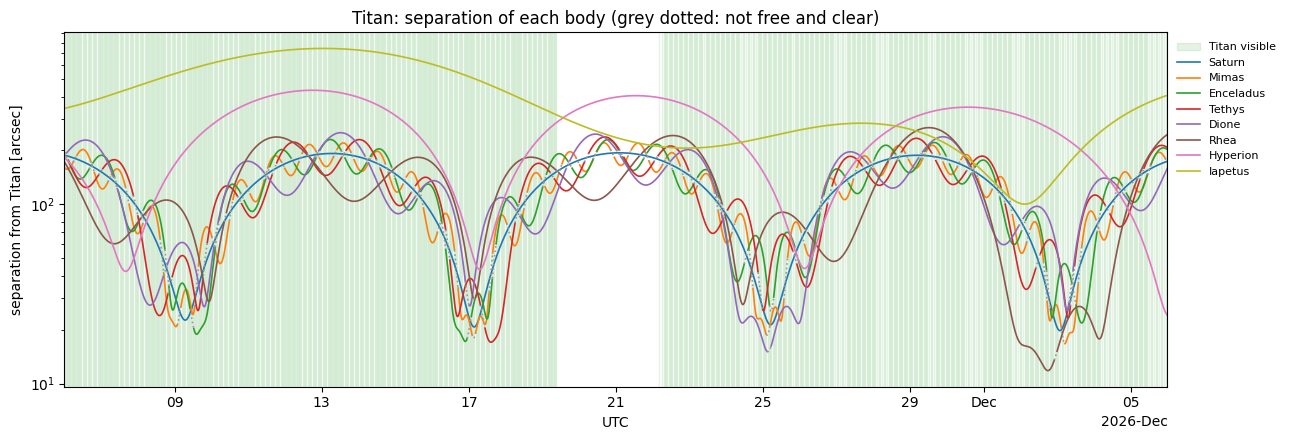

In [5]:
# Table rows every print_step_minutes (rounded to a multiple of the cadence)
print_step_minutes = 120.0
every = max(1, int(round(print_step_minutes / time_step_minutes)))
dates = times.to_datetime()

for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = results[label]["visible"]
    pointing = SkyCoord(*pandora_centric(ephemeris, visibility, times), unit="deg")
    geocentric = SkyCoord(ephemeris["ra"], ephemeris["dec"], unit="deg")
    others = [body_id for body_id in system_ids(target_id) if body_id != target_id]
    separation = {
        body_id: geocentric.separation(
            SkyCoord(ephemerides[body_id]["ra"], ephemerides[body_id]["dec"], unit="deg")
        ).arcsec
        for body_id in others
    }
    clear = {body_id: is_clear(body_id, ephemerides[body_id]) for body_id in others}
    rate = pointing[1:].separation(pointing[:-1]).arcsec / (time_step_minutes / 60.0)
    # The pointing as an ICRF (J2000 ECI) unit vector, one (x, y, z) row per step
    unit_xyz = pointing.cartesian.xyz.value.T

    print(f"\n{label}: Pandora-centric pointing (astrometric ICRF) and "
          f"separations of the other bodies [arcsec]")
    print(f"  moves {np.median(rate):.1f}\"/h on the sky (up to {rate.max():.1f}\"/h); "
          f"Pandora's parallax shifts it up to "
          f"{pointing.separation(geocentric).arcsec.max():.1f}\" from the geocentric position")
    print("  x, y, z: the pointing as a J2000 ECI (ICRF) unit vector")
    print(f"  {'UTC':<17}{'vis':>4}{'RA [deg]':>12}{'Dec [deg]':>11}"
          f"{'x':>17}{'y':>17}{'z':>17}   "
          f"{'RA (hms)':<14}{'Dec (dms)':<14}"
          + "".join(f"{labels[body_id]:>12}" for body_id in others))
    for index in range(0, len(times), every):
        ra_hms, dec_dms = pointing[index].to_string("hmsdms", precision=1).split()
        row = "".join(
            f"{separation[body_id][index]:>10.1f} "
            f"{'' if clear[body_id][index] else ephemerides[body_id]['code'][index]:1}"
            for body_id in others
        )
        print(f"  {times[index].iso[:16]:<17}{'yes' if visible[index] else '':>4}"
              f"{pointing[index].ra.deg:>12.5f}{pointing[index].dec.deg:>+11.5f}"
              + "".join(f"{value:>+17.12f}" for value in unit_xyz[index]) + "   "
              f"{ra_hms:<14}{dec_dms:<14}{row}")

    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.fill_between(dates, 0, 1, where=visible, transform=ax.get_xaxis_transform(),
                    color="tab:green", alpha=0.12, step="mid", label=f"{label} visible")
    # tab10 without its grey, which here means "not free and clear"
    colors = [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7]
    for body_id, color in zip(others, colors):
        ax.plot(dates, np.where(clear[body_id], separation[body_id], np.nan),
                lw=1.2, color=color, label=labels[body_id])
        ax.plot(dates, np.where(clear[body_id], np.nan, separation[body_id]),
                lw=1.2, color="0.6", linestyle=":")
    ax.set_yscale("log")
    ax.set_ylabel(f"separation from {label} [arcsec]")
    ax.set_title(f"{label}: separation of each body (grey dotted: not free and clear)")
    format_date_axis(ax, times)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    plt.tight_layout()

## When is each target visible, and which bodies are clear?

One plot per target. The first row is the target itself; the rows below are the other bodies of its system. A blue box marks when that body is free and clear (not transiting, occulted or eclipsed; a planet always is), and the green line marks when it is **observable**: the target is visible *and* that body is clear. For a moon target, its own row therefore shows when it can actually be observed; for a planet target, the moon rows show when each moon is in view beside it.



 606 Titan
2026-11-06T00:00:00.000: False 117.0
2026-11-06T00:03:00.000: False 117.0
2026-11-06T00:06:00.000: False 117.0
2026-11-06T00:09:00.000: False 117.0
2026-11-06T00:12:00.000: False 117.0
2026-11-06T00:15:00.000: False 117.0
2026-11-06T00:18:00.000: False 117.0
2026-11-06T00:21:00.000: False 117.0
2026-11-06T00:24:00.000: False 117.0
2026-11-06T00:27:00.000: False 117.0
2026-11-06T00:30:00.000: False 117.0
2026-11-06T00:33:00.000: False 117.0
2026-11-06T00:36:00.000: False 117.0
2026-11-06T00:39:00.000: False 117.0
2026-11-06T00:42:00.000: True 117.0
2026-11-06T00:45:00.000: True 117.0
2026-11-06T00:48:00.000: True 117.0
2026-11-06T00:51:00.000: True 117.0
2026-11-06T00:54:00.000: True 117.0
2026-11-06T00:57:00.000: True 117.0
2026-11-06T01:00:00.000: True 117.0
2026-11-06T01:03:00.000: True 117.0
2026-11-06T01:06:00.000: True 117.0
2026-11-06T01:09:00.000: True 117.0
2026-11-06T01:12:00.000: True 117.0
2026-11-06T01:15:00.000: True 117.0
2026-11-06T01:18:00.000: True 117.0
2

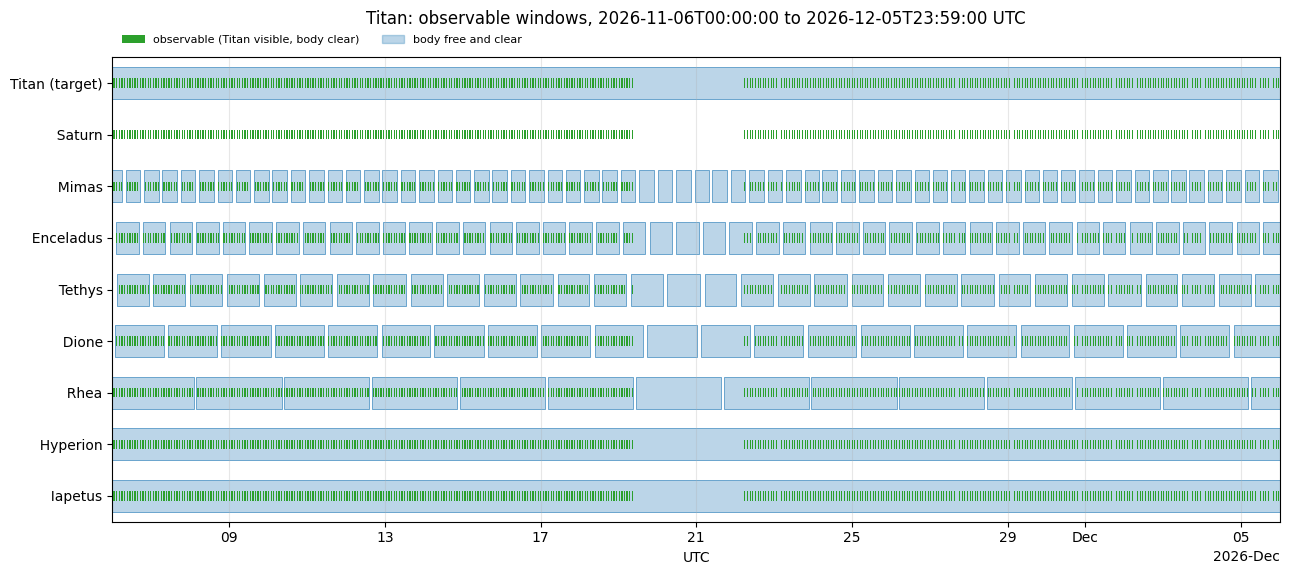

In [6]:
CLEAR_COLOR = "tab:blue"

for target_id, label in targets:
    result = results[label]
    bodies = [target_id] + [b for b in system_ids(target_id) if b != target_id]
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(bodies) + 1.8))
    for row, body_id in enumerate(bodies):
        clear = is_clear(body_id, ephemerides[body_id])
        if not is_primary(body_id):
            draw_event_box(
                ax, row, mask_segments(times, clear, time_step_minutes), CLEAR_COLOR
            )
        draw_row(
            ax, row,
            mask_segments(times, result["visible"] & clear, time_step_minutes),
            "tab:green",
        )
    label_rows(ax, [labels[target_id] + " (target)"]
               + [f"  {labels[body_id]}" for body_id in bodies[1:]])
    format_date_axis(ax, times)
    ax.set_title(f"{label}: observable windows, {start_utc} to {stop_utc} UTC", pad=24)
    handles = [
        Patch(facecolor="tab:green", label=f"observable ({label} visible, body clear)"),
        Patch(facecolor=CLEAR_COLOR, alpha=0.30, edgecolor=CLEAR_COLOR,
              label="body free and clear"),
    ]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
              ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()
for target_id, label in targets:
    print("\n\n", target_id, label)
    result = results[label]
    for time, vis, roll in zip(times, result["visible"], result['roll_deg']):
        print(f"{time}: {vis} {roll}")

## Which constraint is failing?

As in `target_visibility.ipynb`: for each target, a bar marks the time steps where that row fails, and the grey row at the bottom is the overall "not visible" result. **Red rows are binding**; **amber rows are per-tracker detail**, binding only when no other tracker covers them (`st_required`). These are the pointing constraints only: whether a moon is occulted or eclipsed is shown in Cell 6, not here.

Titan: not visible at 8815 of 14400 steps
    moon           fails at  1348 steps
    sun            fails at     0 steps
    earthlimb      fails at  7426 steps
    star tracker   fails at  5469 steps (needs either tracker)
      ST1 sun      < 50 deg at   281 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at  7868 steps
      ST2 sun      < 50 deg at  6240 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at  7749 steps


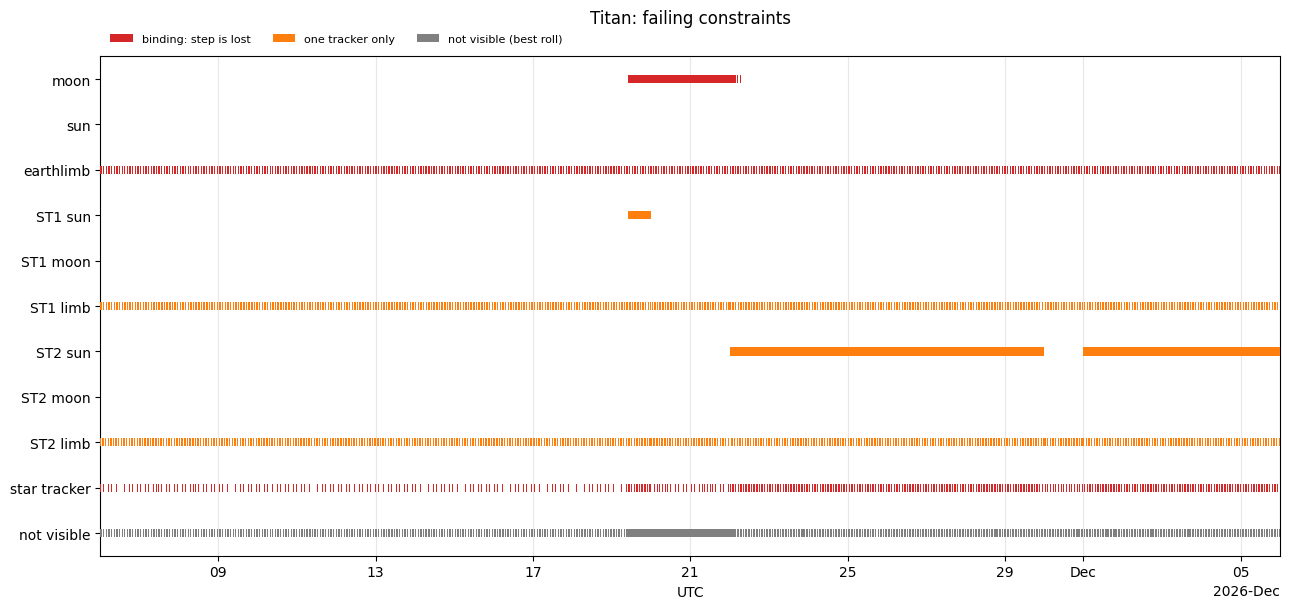

In [7]:
BINDING_COLOR = "tab:red"
TRACKER_COLOR = "tab:orange"

for label, result in results.items():
    not_visible = ~result["visible"]
    binding = {
        name.replace("_", " "): ~passed for name, passed in result["constraints"].items()
    }
    detail = {
        name: ~passed
        for name, passed in result["tracker_checks"].items()
        if name not in ("ST1", "ST2", "combined")
    }
    explained = np.zeros_like(not_visible)
    for fail_mask in binding.values():
        explained |= fail_mask
    unexplained = int(np.sum(not_visible & ~explained))

    boresight = [name for name in binding if name != "star tracker"]
    st_rows = ["star tracker"] if "star tracker" in binding else []
    rows = boresight + list(detail) + st_rows + ["not visible"]

    fig, ax = plt.subplots(figsize=(13, 0.4 * len(rows) + 1.8))
    for row, name in enumerate(rows):
        if name == "not visible":
            mask, color = not_visible, "0.5"
        elif name in detail:
            mask, color = detail[name], TRACKER_COLOR
        else:
            mask, color = binding[name], BINDING_COLOR
        draw_row(ax, row, mask_segments(times, mask, time_step_minutes), color)
    label_rows(ax, rows)
    format_date_axis(ax, times)
    ax.set_title(f"{label}: failing constraints", pad=24 if detail else 6)
    if detail:
        handles = [
            Patch(facecolor=BINDING_COLOR, label="binding: step is lost"),
            Patch(facecolor=TRACKER_COLOR, label="one tracker only"),
            Patch(facecolor="0.5", label="not visible (best roll)"),
        ]
        ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
                  ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()

    print(f"{label}: not visible at {int(not_visible.sum())} of {len(times)} steps")
    for name in boresight:
        print(f"    {name:<14} fails at {int(binding[name].sum()):>5} steps")
    if detail:
        need = "both trackers" if visibility.st_required == 2 else "either tracker"
        print(f"    {'star tracker':<14} fails at "
              f"{int(binding['star tracker'].sum()):>5} steps (needs {need})")
        for name, mask in detail.items():
            print(f"      {name:<12} < {result['limits'][name].value:.0f} deg at "
                  f"{int(mask.sum()):>5} steps")
    if unexplained:
        print(f"    WARNING: {unexplained} not-visible steps are not explained "
              f"by any row above; the rows and the result have diverged")

## The NIRDA subarray each day

For each target and each day it is visible, the simulated `nirda_roi_x` x `nirda_roi_y` subarray at the roll held that day, at the middle visible time step (`trace.plot_trace`). The target sits at the pivot; the other bodies of its system and the Gaia field stars (J < 14) are drawn as traces, labeled by name or J. The dashed box is the target's extraction aperture, and each title gives the time, the roll and the trace contamination of that aperture (worst spectral channel, within ±1° of roll error).

Approximations, all in `solar_system_helpers.py`:
- A body wider than two pixels (here only the planet) is a uniform oblate disk, plus Saturn's A and B rings at the Horizons ring opening angle with the disk's surface brightness. Ring shadows, the disk hidden behind the rings and limb darkening are ignored.
- Brightness ratios use J = V - 1.15 (sunlight's color) from Horizons' visual magnitudes. Methane bands make Saturn and Titan fainter in the near infrared than that.
- A moon occulted by its planet or fully eclipsed is left out of the panel; a partially eclipsed or transiting moon is drawn at its Horizons magnitude.

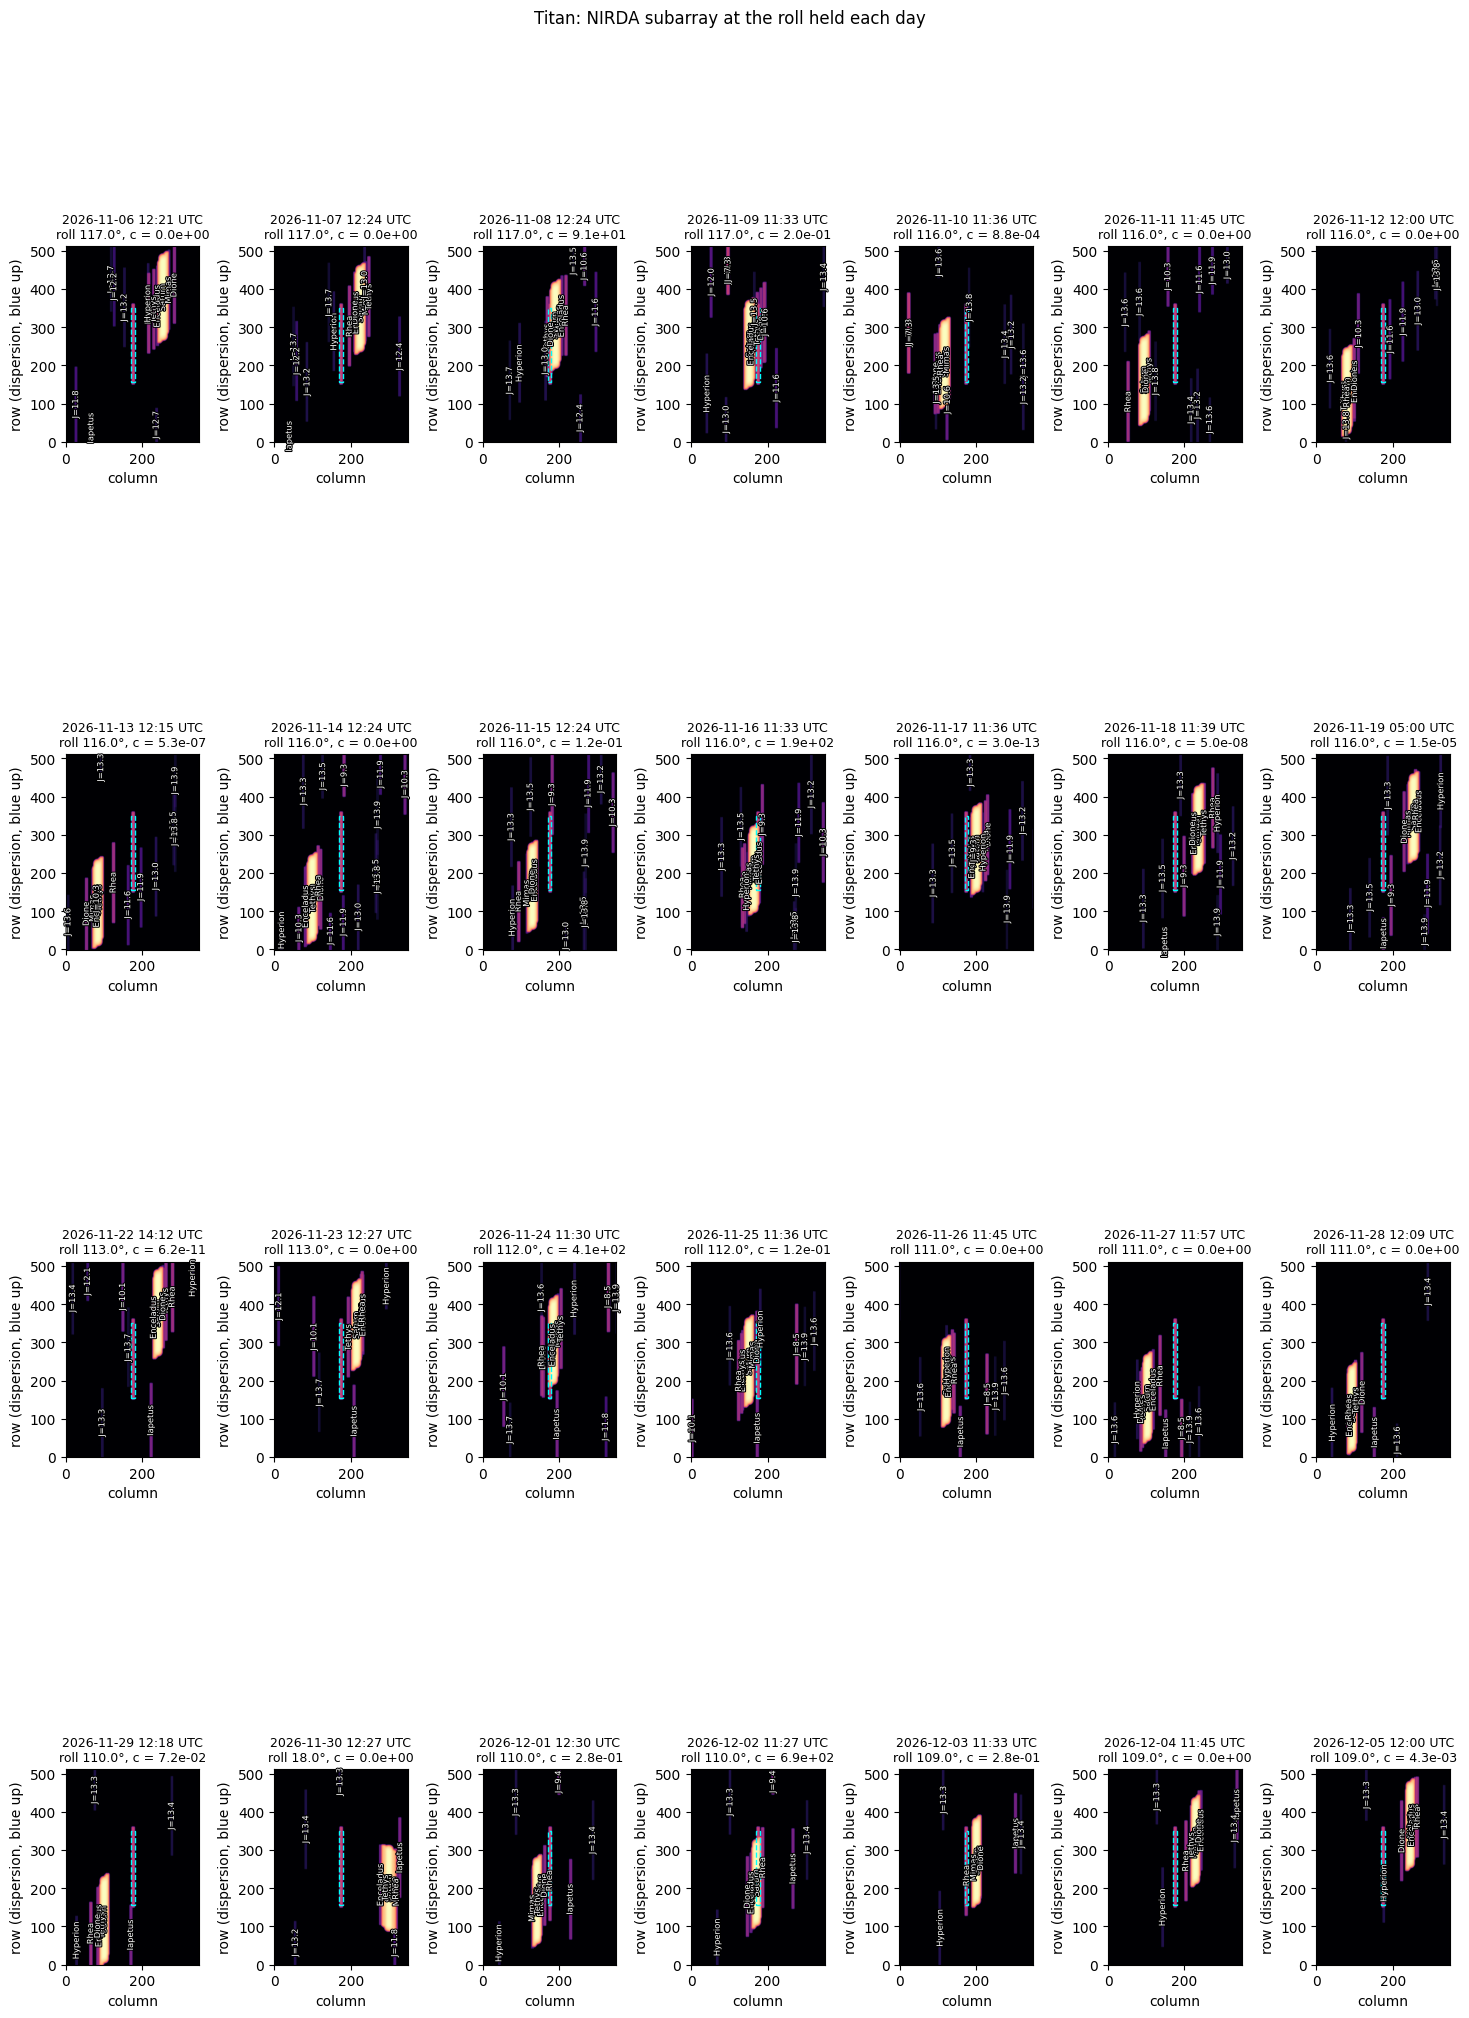

In [8]:
n_columns = 7
for target_id, label in targets:
    result = results[label]
    # Middle visible step of each day
    panels = []
    for day in days:
        indices = np.flatnonzero((day_of == day) & result["visible"])
        if indices.size:
            panels.append(indices[indices.size // 2])
    if not panels:
        print(f"{label}: not visible on any day, so no subarray panels")
        continue

    n_rows = int(np.ceil(len(panels) / n_columns))
    fig, axes = plt.subplots(
        n_rows, n_columns, figsize=(2.1 * n_columns, 5.4 * n_rows), squeeze=False
    )
    for ax, index in zip(axes.flat, panels):
        field = system_field(
            target_id, ephemerides, index, times[index], labels,
            include_stars=include_field_stars,
        )
        trace.plot_trace(
            field,
            result["roll_deg"][index] * u.deg,
            visibility.nirda_roi_x,
            visibility.nirda_roi_y,
            ax=ax,
            title=f"{times[index].iso[:16]} UTC",
        )
    for ax in axes.flat[len(panels):]:
        ax.set_axis_off()
    fig.suptitle(f"{label}: NIRDA subarray at the roll held each day", y=1.0)
    plt.tight_layout()

## The VISDA field each day

For each target and each day it is visible, the simulated VISDA (visible camera) field at the roll held that day and the same time step as the NIRDA panels (`visda.plot_visible_field`), as one uncoadded 0.2 s frame with read noise. The target is centered in the red box (`visda_target_box` pixels, at `visda_target_pixel`, None for the field center), and the blue box is `visda_center_box` pixels about the field center. The bodies of its system that are not hidden are drawn with the same disk and ring samples as the NIRDA panels and labeled by name, and Gaia stars brighter than `visda_bp_limit` in BP are added (labeled when brighter than BP 12). White contours outline where the model saturates (a planet's disk and rings), and orange circles mark stars whose brightest pixel likely saturates. The camera model is described in `target_visibility.ipynb`.

Bodies take Gaia G = V - 0.15 and BP - RP = 0.82 (sunlight's color) from Horizons' visual magnitudes.

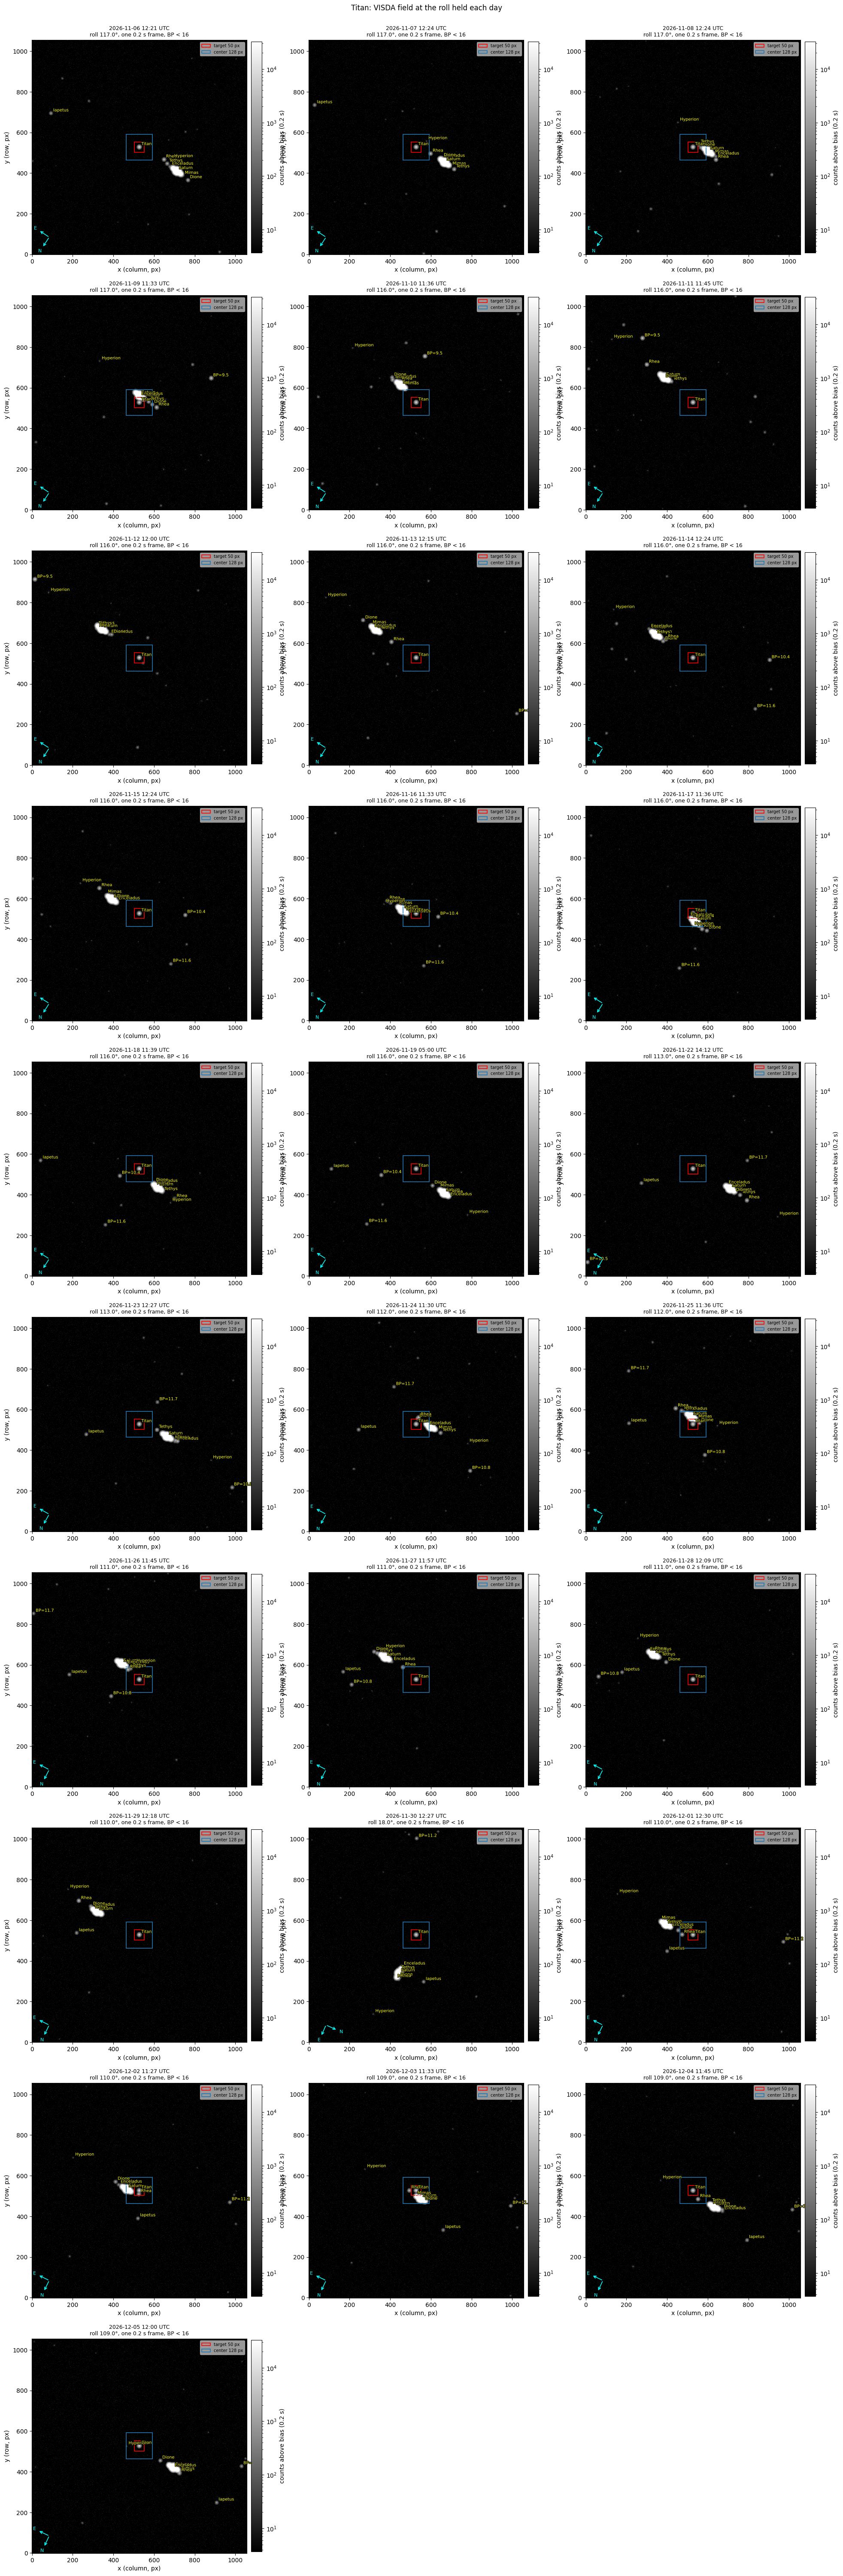

In [9]:
# VISDA field settings, as in target_visibility.ipynb: the field's (x, y) size
# in pixels; the target's pixel in it (None for the field center); the sides
# in pixels of the red box on the target and the blue box on the field center;
# and the faintest Gaia BP drawn.
visda_field_size = (1056, 1056)
visda_target_pixel = None
visda_target_box = 50
visda_center_box = 128
visda_bp_limit = 16.0

radius_arcmin = visda.field_radius_arcmin(visda_field_size, visda_target_pixel)
n_columns = 3
for target_id, label in targets:
    result = results[label]
    # Middle visible step of each day, as in the NIRDA panels
    panels = []
    for day in days:
        indices = np.flatnonzero((day_of == day) & result["visible"])
        if indices.size:
            panels.append(indices[indices.size // 2])
            # panels.append(indices[indices.size // 2 + 1])
    if not panels:
        print(f"{label}: not visible on any day, so no VISDA panels")
        continue

    n_rows = int(np.ceil(len(panels) / n_columns))
    fig, axes = plt.subplots(
        n_rows, n_columns, figsize=(6.5 * n_columns, 6.0 * n_rows), squeeze=False
    )
    for ax, index in zip(axes.flat, panels):
        sources = system_visible_sources(
            target_id, ephemerides, index, times[index], labels, radius_arcmin,
            include_stars=include_field_stars,
        )
        visda.plot_visible_field(
            sources,
            result["roll_deg"][index] * u.deg,
            field_size=visda_field_size,
            target_pixel=visda_target_pixel,
            target_box=visda_target_box,
            center_box=visda_center_box,
            bp_limit=visda_bp_limit,
            ax=ax,
            title=f"{times[index].iso[:16]} UTC",
        )
    for ax in axes.flat[len(panels):]:
        ax.set_axis_off()
    fig.suptitle(f"{label}: VISDA field at the roll held each day", y=1.0)
    plt.tight_layout()

## Save one CSV per target

One row per time step of Cell 2's grid, written beside this notebook as `<target>.csv` (git ignores `docs/*.csv`), overwriting an earlier run's file:

- `datetime`: UTC, ISO format
- `visible`: True or False
- `RA`, `DEC`: the Pandora-centric pointing at that step (as in Cell 5) in decimal degrees
- `X`, `Y`, `Z`: the same direction as a J2000 ECI (ICRF) unit vector, 12 decimals
- `Roll`: the roll held, in degrees (the roll held that day, as in Cell 4)


In [10]:
# One CSV per target, written beside this notebook
for target_id, label in targets:
    result = results[label]
    ra_deg, dec_deg = pandora_centric(ephemerides[target_id], visibility, times)
    unit_xyz = SkyCoord(ra_deg, dec_deg, unit="deg").cartesian.xyz.value.T
    path = Path(f"{label.replace(' ', '_')}.csv")
    with open(path, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["datetime", "visible", "RA", "DEC", "X", "Y", "Z", "Roll"])
        for index, time in enumerate(times.isot):
            writer.writerow(
                [time, bool(result["visible"][index]),
                 f"{ra_deg[index]:.8f}", f"{dec_deg[index]:.8f}"]
                + [f"{value:.12f}" for value in unit_xyz[index]]
                + [f"{result['roll_deg'][index]:.4f}"]
            )
    print(f"{label}: {len(times)} rows -> {path.resolve()}")

Titan: 14400 rows -> C:\Gits\pandora-visibility\docs\Titan.csv


## When is each target observable, and where is it in its orbit?

For each target, the steps it can be observed: visible (Cell 4), free and clear (`require_clear`), and, for a moon with `exclude_near_host` on, not within `host_cone_deg` of straight in front of or behind its planet, where the planet's light would swamp it. Printed as a list of windows, then a row every `observable_print_step_minutes` with the pointing, and saved in full to `<target>_observable.csv` beside this notebook. Plots show each moon's orbital phase and its separation from its planet (arcmin, with the planet's radius dashed) over time and, for every target, how much of its disk is sunlit as seen from Pandora.

Geometry, all as seen from Pandora:
- **orbital phase**: the moon's place in its orbit, 0° straight in front of the planet (inferior conjunction), then in its direction of motion: 90° and 270° are the greatest elongations, 180° is behind the planet.
- **host angle**: the angle at the planet between the moon and Pandora, 0° in front and 180° behind. The cone test uses it, so it also counts the tilt of the orbit to the line of sight: Horizons' transits sit at 5-19° and its occultations at 160-173° for Saturn's inner moons in late 2026.
- **phase angle**: Sun-target-Pandora (Horizons, geocentric). It is under 6° for Saturn from near Earth, so the target is always nearly full.
- **sunlit disk**: the lit share of the disk, (1 + cos(phase angle)) / 2, times the disk's projected area (Horizons' angular diameter of the solid surface, flattened for an oblate planet), in square arcsec on the sky and square km on the body. It is zero while Horizons has the target behind its planet or fully in its shadow. Partial eclipses are marked but their loss is not modeled, and Saturn's rings are not counted. From near Earth the lit share stays above 99.7%, so the area mostly tracks the target's distance.

**Glint**: sunlight reflects specularly off a liquid surface at the point whose normal bisects the directions to the Sun and Pandora, at an angle of incidence of half the phase angle. `glint_possible` is True when that point lies within `glint_tolerance_deg` of a sea or lake in `LIQUID_FEATURES` (`solar_system_helpers.py`; only Titan's are listed, as circles about their centers). The Fresnel reflectance there uses `liquid_refractive_index` (default 1.29, a methane-ethane mix). From near Earth the specular point stays within about 30° of Titan's equator (it follows the sub-Earth latitude, at most ±27°), while its seas lie poleward of about 55°, so a glint is not possible from Pandora; the table gives how far away the nearest one is. Glints off Titan's seas also need near-infrared light (the 1.3 or 1.6 µm windows): its haze hides the surface from VISDA.


Titan: observable at 4203 of 14400 steps (visible 5585; and free and clear 5585; and outside the 20 deg host cones 4203)
  glint: specular point at -7.5 to -7.4 deg latitude, 63.0 to 92.2 deg from the edge of the nearest sea (tolerance 5); possible at 0 observable steps; reflectance 0.0160 (n = 1.29)
  sunlit disk while observable: 99.772 to 99.911% lit, 0.4908 to 0.5364 sq arcsec (2.0801e+07 sq km)
  start UTC        stop UTC            min     phase [deg]   host [deg]   roll  glint
  2026-11-06 00:42 2026-11-06 01:30     51      290 -> 291       69- 70   +117       
  2026-11-06 02:18 2026-11-06 03:06     51      291 -> 292       68- 69   +117       
  2026-11-06 03:54 2026-11-06 04:42     51      293 -> 294       67- 67   +117       
  2026-11-06 05:33 2026-11-06 06:18     48      294 -> 295       65- 66   +117       
  2026-11-06 07:09 2026-11-06 07:57     51      296 -> 297       64- 64   +117       
  2026-11-06 08:45 2026-11-06 09:33     51      297 -> 298       62- 63   +117  

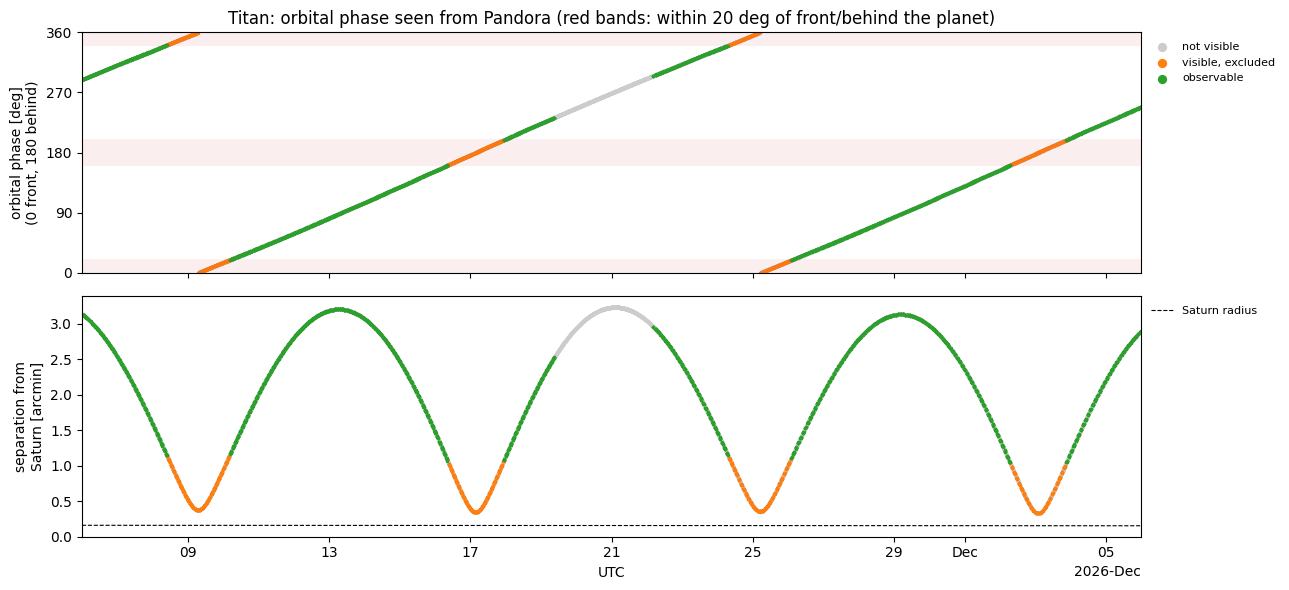

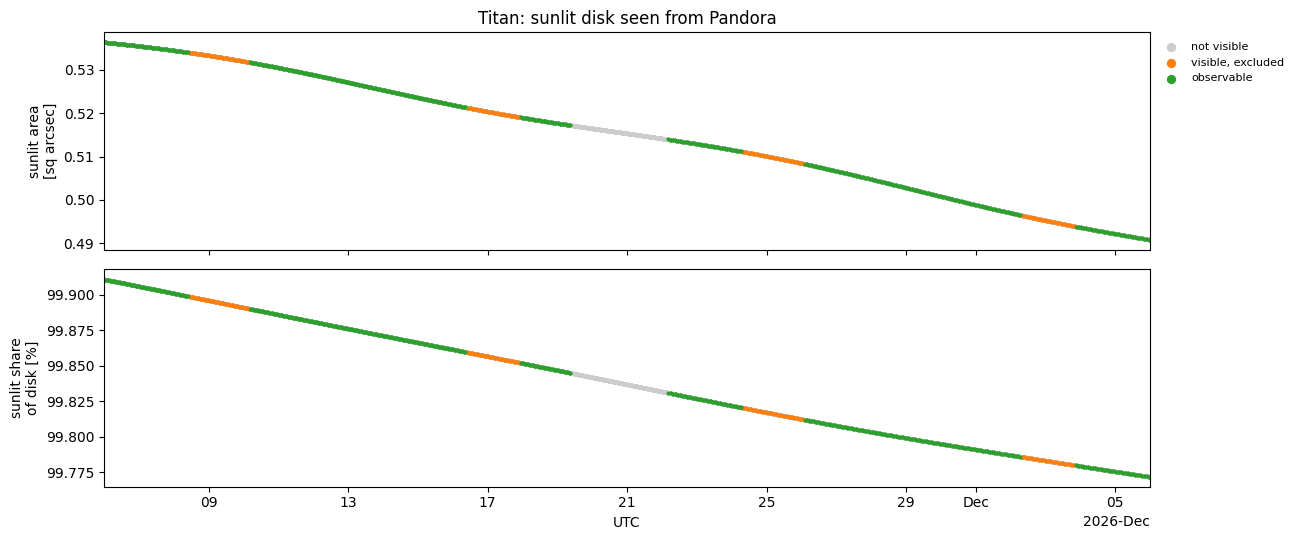

In [11]:
# Settings
require_clear = True        # drop steps Horizons marks occulted, transiting or eclipsed
exclude_near_host = True    # drop steps a moon is near straight in front of or behind its planet
host_cone_deg = 20.0        # half-angle of that cone, deg
glint_tolerance_deg = 5.0   # allowed arc from a sea's edge to the specular point, deg
liquid_refractive_index = TITAN_LIQUID_INDEX
observable_print_step_minutes = 30.0

every = max(1, int(round(observable_print_step_minutes / time_step_minutes)))
for target_id, label in targets:
    result = results[label]
    ephemeris = ephemerides[target_id]
    is_moon = not is_primary(target_id)
    ra_deg, dec_deg = pandora_centric(ephemeris, visibility, times)
    unit_xyz = SkyCoord(ra_deg, dec_deg, unit="deg").cartesian.xyz.value.T
    specular_lat, specular_lon, incidence = specular_point(ephemeris)
    glint, glint_feature, glint_distance = glint_check(
        target_id, ephemeris, glint_tolerance_deg
    )
    reflectance = fresnel_reflectance(incidence, liquid_refractive_index)
    disk = illuminated_disk(target_id, ephemeris)
    if is_moon:
        geometry = moon_geometry(target_id, ephemerides, visibility, times)
        # Separation from the planet's center on the sky, both seen from Pandora
        host_id = system_ids(target_id)[0]
        host_ra, host_dec = pandora_centric(ephemerides[host_id], visibility, times)
        host_separation = SkyCoord(ra_deg, dec_deg, unit="deg").separation(
            SkyCoord(host_ra, host_dec, unit="deg")).arcmin
    else:
        geometry = {key: np.full(len(times), np.nan) for key in ("host_angle", "orbital_phase")}
        host_separation = np.full(len(times), np.nan)

    # Each exclusion counted among the steps the ones before it left
    observable = result["visible"].copy()
    counts = [("visible", int(observable.sum()))]
    if require_clear:
        observable &= is_clear(target_id, ephemeris)
        counts.append(("and free and clear", int(observable.sum())))
    near_host = (geometry["host_angle"] < host_cone_deg) | (
        geometry["host_angle"] > 180.0 - host_cone_deg
    )
    if is_moon and exclude_near_host:
        observable &= ~near_host
        counts.append((f"and outside the {host_cone_deg:g} deg host cones", int(observable.sum())))

    print(f"\n{label}: observable at {observable.sum()} of {len(times)} steps ("
          + "; ".join(f"{name} {count}" for name, count in counts) + ")")
    if LIQUID_FEATURES.get(target_id):
        print(f"  glint: specular point at {specular_lat.min():+.1f} to {specular_lat.max():+.1f} deg latitude, "
              f"{glint_distance.min():.1f} to {glint_distance.max():.1f} deg from the edge of the nearest sea "
              f"(tolerance {glint_tolerance_deg:g}); possible at {int((glint & observable).sum())} observable steps; "
              f"reflectance {reflectance.min():.4f} (n = {liquid_refractive_index:g})")
    if observable.any():
        lit = disk["lit_area_arcsec2"][observable]
        print(f"  sunlit disk while observable: {100 * disk['lit_fraction'][observable].min():.3f} to "
              f"{100 * disk['lit_fraction'][observable].max():.3f}% lit, {lit.min():.4f} to {lit.max():.4f} "
              f"sq arcsec ({disk['lit_area_km2'][observable].mean():.4e} sq km)")
    if not observable.any():
        continue

    # Windows: runs of consecutive observable steps
    edges = np.flatnonzero(np.diff(np.r_[0, observable.astype(int), 0]))
    print(f"  {'start UTC':<17}{'stop UTC':<17}{'min':>6}{'phase [deg]':>16}{'host [deg]':>13}"
          f"{'roll':>7}{'glint':>7}")
    for start, stop in zip(edges[::2], edges[1::2] - 1):
        span = slice(start, stop + 1)
        phase_text = (f"{geometry['orbital_phase'][start]:5.0f} -> {geometry['orbital_phase'][stop]:3.0f}"
                      if is_moon else "")
        host_text = (f"{geometry['host_angle'][span].min():4.0f}-{geometry['host_angle'][span].max():3.0f}"
                     if is_moon else "")
        print(f"  {times[start].iso[:16]:<17}{times[stop].iso[:16]:<17}"
              f"{(stop - start + 1) * time_step_minutes:>6.0f}{phase_text:>16}{host_text:>13}"
              f"{result['roll_deg'][start]:>+7.0f}{'yes' if glint[span].any() else '':>7}")

    print(f"\n  Every {every * time_step_minutes:g} min while observable "
          f"(RA/Dec Pandora-centric ICRF; specular point lat, lon in Horizons' convention for the body)")
    print(f"  {'UTC':<17}{'RA [deg]':>12}{'Dec [deg]':>11}{'phase':>7}{'host':>6}{'S-T-O':>7}"
          f"{'specular':>16}{'roll':>7}{'glint':>7}")
    for index in np.flatnonzero(observable & (np.arange(len(times)) % every == 0)):
        print(f"  {times[index].iso[:16]:<17}{ra_deg[index]:>12.5f}{dec_deg[index]:>+11.5f}"
              + (f"{geometry['orbital_phase'][index]:>7.1f}{geometry['host_angle'][index]:>6.1f}"
                 if is_moon else " " * 13)
              + f"{ephemeris['phase_angle'][index]:>7.2f}"
              f"{specular_lat[index]:>+8.1f}{specular_lon[index]:>8.1f}"
              f"{result['roll_deg'][index]:>+7.0f}{'yes' if glint[index] else '':>7}")

    # Every observable step to CSV
    path = Path(f"{label.replace(' ', '_')}_observable.csv")
    with open(path, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["datetime", "RA", "DEC", "X", "Y", "Z", "Roll", "orbital_phase",
                         "host_angle", "host_separation_arcmin", "phase_angle", "specular_lat", "specular_lon",
                         "glint_possible", "glint_reflectance", "lit_fraction",
                         "lit_area_arcsec2", "lit_area_km2"])
        for index in np.flatnonzero(observable):
            writer.writerow(
                [times[index].isot, f"{ra_deg[index]:.8f}", f"{dec_deg[index]:.8f}"]
                + [f"{value:.12f}" for value in unit_xyz[index]]
                + [f"{result['roll_deg'][index]:.4f}",
                   f"{geometry['orbital_phase'][index]:.3f}", f"{geometry['host_angle'][index]:.3f}",
                   f"{host_separation[index]:.5f}",
                   f"{ephemeris['phase_angle'][index]:.4f}", f"{specular_lat[index]:.3f}",
                   f"{specular_lon[index]:.3f}", bool(glint[index]), f"{reflectance[index]:.5f}",
                   f"{disk['lit_fraction'][index]:.6f}", f"{disk['lit_area_arcsec2'][index]:.6f}",
                   f"{disk['lit_area_km2'][index]:.6e}"]
            )
    print(f"  {int(observable.sum())} rows -> {path.resolve()}")

    if is_moon:
        fig, (ax, ax_separation) = plt.subplots(2, 1, figsize=(13, 6.0), sharex=True)
        dates = times.to_datetime()
        states = (
            (~result["visible"], "0.8", "not visible"),
            (result["visible"] & ~observable, "tab:orange", "visible, excluded"),
            (observable, "tab:green", "observable"),
        )
        for mask, color, name in states:
            ax.scatter(dates[mask], geometry["orbital_phase"][mask], s=2, color=color, label=name)
            ax_separation.scatter(dates[mask], host_separation[mask], s=2, color=color)
        # The planet's equatorial radius, for scale against its glare
        ax_separation.plot(dates, 0.5 * ephemerides[host_id]["diameter"] / 60.0, color="k",
                           linestyle="--", lw=0.8, label=f"{labels[host_id]} radius")
        ax_separation.set_ylim(bottom=0)
        ax_separation.set_ylabel(f"separation from\n{labels[host_id]} [arcmin]")
        ax_separation.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8,
                             frameon=False)
        if exclude_near_host:
            for low, high in ((0, host_cone_deg), (180 - host_cone_deg, 180 + host_cone_deg),
                              (360 - host_cone_deg, 360)):
                ax.axhspan(low, high, color="tab:red", alpha=0.08, lw=0)
        ax.set_ylim(0, 360)
        ax.set_yticks([0, 90, 180, 270, 360])
        ax.set_ylabel("orbital phase [deg]\n(0 front, 180 behind)")
        ax.set_title(f"{label}: orbital phase seen from Pandora "
                     f"(red bands: within {host_cone_deg:g} deg of front/behind the planet)")
        format_date_axis(ax_separation, times)
        ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False,
                  markerscale=4)
        plt.tight_layout()

    # Sunlit disk over time, for every target
    fig, (ax_area, ax_fraction) = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
    dates = times.to_datetime()
    states = (
        (~result["visible"], "0.8", "not visible"),
        (result["visible"] & ~observable, "tab:orange", "visible, excluded"),
        (observable, "tab:green", "observable"),
    )
    shown = ~disk["hidden"]
    for axis, values in ((ax_area, disk["lit_area_arcsec2"]), (ax_fraction, 100 * disk["lit_fraction"])):
        for mask, color, name in states:
            axis.scatter(dates[mask & shown], values[mask & shown], s=2, color=color, label=name)
        # Hidden (lit area 0) and partially eclipsed steps as bands, so the
        # axis can zoom on the lit values
        for mask, color, name in ((disk["hidden"], "tab:red", "occulted or fully eclipsed (0)"),
                                  (disk["partial"], "tab:purple", "partial eclipse (not modeled)")):
            if mask.any():
                axis.fill_between(dates, 0, 1, where=mask, transform=axis.get_xaxis_transform(),
                                  color=color, alpha=0.2, step="mid", lw=0, label=name)
    if shown.any():
        for axis, values in ((ax_area, disk["lit_area_arcsec2"]), (ax_fraction, 100 * disk["lit_fraction"])):
            low, high = values[shown].min(), values[shown].max()
            pad = max(0.05 * (high - low), 1e-6 * high)
            axis.set_ylim(low - pad, high + pad)
            axis.ticklabel_format(axis="y", useOffset=False)
    ax_area.set_ylabel("sunlit area\n[sq arcsec]")
    ax_fraction.set_ylabel("sunlit share\nof disk [%]")
    ax_area.set_title(f"{label}: sunlit disk seen from Pandora")
    format_date_axis(ax_fraction, times)
    ax_area.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False,
                   markerscale=4)
    plt.tight_layout()